# SLSV 模型（对称 LSV 模型）

**行为金融因子 —— 羊群效应（基金买卖方向识别）**

SLSV 模型在 LSV 模型的基础上引入方向符号，以区分基金的买入从众和卖出从众行为：

$$
\text{SLSV}_{i,t} =\begin{cases}\text{LSV}_{i,t}, & p_{i,t} > p_t, \\-\text{LSV}_{i,t}, & p_{i,t} < p_t\end{cases}
$$

其中，$\text{LSV}_{i,t}$ 为 LSV 模型的核心指标，计算方式如下：

$$
\text{LSV}_{i,t} = \left| p_{i,t} - p_t \right| - \mathbb{E}\left| p_{i,t} - p_t \right|
$$

期望绝对偏差项在无羊群效应假设下计算：

$$
\mathbb{E}\left| p_{i,t} - p_t \right| = \text{AF}(i,t) = \sum_{k=1}^{N_{i,t}} \binom{N_{i,t}}{k} p_t^k (1 - p_t)^{N_{i,t}-k} \left| \frac{k}{N_{i,t}} - p_t \right|
$$

各基础变量定义如下：

$$
p_{i,t} = \frac{B(i,t)}{B(i,t) + S(i,t)}
$$$$
p_t = \frac{\sum_{i=1}^{N} p_{i,t}}{N}
$$$$
N_{i,t} = B(i,t) + S(i,t)
$$

其中：

* $B(i,t)$ 为在区间 $t$ 内买入股票 $i$ 的基金数量（即报告期持仓相较上期增加的基金数）；
* $S(i,t)$ 为在区间 $t$ 内卖出股票 $i$ 的基金数量（即报告期持仓相较上期减少的基金数）；
* $N_{i,t}$ 为持仓发生变动的基金总数（买入基金与卖出基金之和）；
* $p_{i,t}$ 为股票 $i$ 在区间 $t$ 内买入基金的占比；
* $p_t$ 为全市场所有股票在区间 $t$ 内买入基金占比的均值（跨股票平均值）；
* $N$ 为全市场股票总数。

## 计算示例

以基金年报或半年报持仓数据为例，若在报告期内有 300 只基金对股票 $i$ 进行了加仓操作，50 只基金进行了减仓操作，则：

$$
B(i,t) = 300,\quad S(i,t) = 50,\quad N_{i,t} = 350
$$$$
p_{i,t} = \frac{300}{350} \approx 0.857
$$

## 因子说明

LSV 模型从基金持股变动数据出发，通过比较某只股票实际被买入的比例与全市场平均买入比例的偏差程度，来判断该股票是否存在基金集中交易行为，从而捕捉基金“抱团”现象。

在此基础上，**SLSV 模型（对称 LSV）进一步考虑了投资者的买卖方向**，对 LSV 指标进行符号化处理：

* 当 $\text{SLSV}_{i,t} > 0$ 时（即 $p_{i,t} > p_t$），表明基金对该股票的买入比例高于市场平均水平，对应**买入从众效应**（集体加仓）；
* 当 $\text{SLSV}_{i,t} < 0$ 时（即 $p_{i,t} < p_t$），表明基金对该股票的买入比例低于市场平均水平（卖出比例更高），对应**卖出从众效应**（集体减仓）。

SLSV 指标的正负方向能够有效区分基金是“集体买入”还是“集体卖出”某只股票，为研究羊群效应的方向性差异提供了更丰富的信息。

数据：基金持仓数据

In [1]:
from pathlib import Path
from math import lgamma

import numpy as np
import pandas as pd


def _slsv_adjustment_factor(n_funds, market_buy_ratio):
    """
    AF(i,t) = E[|K / N - p_t|]
    K ~ Binomial(N, p_t)

    注意：这里包含 K=0 项，符合完整的二项分布期望。
    """
    if n_funds <= 0:
        return np.nan

    if market_buy_ratio <= 0.0 or market_buy_ratio >= 1.0:
        return 0.0

    k = np.arange(n_funds + 1, dtype=float)

    log_combination = np.array([
        lgamma(n_funds + 1)
        - lgamma(int(value) + 1)
        - lgamma(n_funds - int(value) + 1)
        for value in k
    ])

    log_probability = (
        log_combination
        + k * np.log(market_buy_ratio)
        + (n_funds - k) * np.log(1.0 - market_buy_ratio)
    )

    probability = np.exp(log_probability)

    return np.sum(
        probability
        * np.abs(k / n_funds - market_buy_ratio)
    )


def _slsv_get_report_files(
    holdings_dir,
    report_months=(6, 12),
):
    """
    返回：
    {report_date: parquet_file_path}
    """
    report_files = {}

    for file_path in Path(holdings_dir).glob("*.parquet"):
        try:
            report_date = pd.Timestamp(file_path.stem)
        except ValueError:
            continue

        if report_date.month in report_months:
            report_files[report_date] = file_path

    if not report_files:
        raise FileNotFoundError(
            "未在 {} 找到报告期持仓文件。".format(
                holdings_dir
            )
        )

    return report_files


def _slsv_read_holding_snapshot(file_path):
    """
    读取一个报告期的基金 A 股持仓，并聚合重复记录。
    """
    required_columns = [
        "fund_id",
        "report_date",
        "release_date",
        "order_book_id",
        "shares",
        "type",
        "category",
    ]

    data = pd.read_parquet(
        file_path,
        columns=required_columns,
    )

    missing_columns = (
        set(required_columns)
        - set(data.columns)
    )

    if missing_columns:
        raise ValueError(
            "{} 缺少字段：{}".format(
                file_path.name,
                sorted(missing_columns),
            )
        )

    data["report_date"] = pd.to_datetime(
        data["report_date"]
    )

    data["release_date"] = pd.to_datetime(
        data["release_date"]
    )

    data["shares"] = pd.to_numeric(
        data["shares"],
        errors="coerce",
    )

    # 仅保留 A 股股票持仓
    data = data[
        data["type"].eq("Stock")
        & data["category"]
        .astype(str)
        .str.lower()
        .eq("ashare")
    ]

    data = data.dropna(
        subset=[
            "fund_id",
            "report_date",
            "release_date",
            "order_book_id",
            "shares",
        ]
    )

    # 同一基金、同一报告期、同一股票出现重复时合并持仓
    data = (
        data
        .groupby(
            ["fund_id", "report_date", "order_book_id"],
            as_index=False,
        )
        .agg(
            shares=("shares", "sum"),
            release_date=("release_date", "max"),
        )
    )

    return data


def _slsv_load_trading_dates(indicators_dir):
    """
    从 comp_con_pe_ftm 文件名提取交易日。

    若目录中存在更多指标文件，也可将 glob 改为 rglob。
    """
    fpe_dir = (
        Path(indicators_dir)
        / "comp_con_pe_ftm"
    )

    trading_dates = []

    for file_path in fpe_dir.glob("*.parquet"):
        try:
            trading_dates.append(
                pd.Timestamp(file_path.stem)
            )
        except ValueError:
            continue

    trading_dates = pd.DatetimeIndex(
        sorted(set(trading_dates))
    )

    if trading_dates.empty:
        raise RuntimeError(
            "无法从 get_comp_indicators/comp_con_pe_ftm "
            "提取交易日。"
        )

    return trading_dates


def _slsv_build_report_factor(
    holdings_dir,
    report_months=(6, 12),
    share_tolerance=1e-8,
):
    """
    按相邻报告期计算 LSV 与 SLSV。

    输出字段：
    B, S, N, p_i, p_t, AF, LSV, SLSV,
    report_date, available_date
    """
    report_files = _slsv_get_report_files(
        holdings_dir=holdings_dir,
        report_months=report_months,
    )

    report_dates = sorted(report_files.keys())

    if len(report_dates) < 2:
        raise RuntimeError(
            "至少需要两个报告期的持仓数据。"
        )

    factor_parts = []

    # 只保留相邻两个报告期在内存中
    previous_date = report_dates[0]

    previous = _slsv_read_holding_snapshot(
        report_files[previous_date]
    )

    for current_date in report_dates[1:]:
        current = _slsv_read_holding_snapshot(
            report_files[current_date]
        )

        # 仅使用两个报告期均有披露持仓的基金
        common_funds = np.intersect1d(
            previous["fund_id"].unique(),
            current["fund_id"].unique(),
        )

        if len(common_funds) > 0:
            previous_common = previous[
                previous["fund_id"].isin(common_funds)
            ]

            current_common = current[
                current["fund_id"].isin(common_funds)
            ]

            merged = pd.merge(
                current_common[
                    ["fund_id", "order_book_id", "shares"]
                ].rename(
                    columns={"shares": "shares_current"}
                ),
                previous_common[
                    ["fund_id", "order_book_id", "shares"]
                ].rename(
                    columns={"shares": "shares_previous"}
                ),
                on=["fund_id", "order_book_id"],
                how="outer",
            )

            merged["shares_current"] = (
                merged["shares_current"].fillna(0.0)
            )

            merged["shares_previous"] = (
                merged["shares_previous"].fillna(0.0)
            )

            holding_change = (
                merged["shares_current"]
                - merged["shares_previous"]
            )

            buy_count = (
                merged.loc[
                    holding_change > share_tolerance
                ]
                .groupby("order_book_id")["fund_id"]
                .nunique()
                .rename("B")
            )

            sell_count = (
                merged.loc[
                    holding_change < -share_tolerance
                ]
                .groupby("order_book_id")["fund_id"]
                .nunique()
                .rename("S")
            )

            stock_changes = pd.concat(
                [buy_count, sell_count],
                axis=1,
            ).fillna(0.0)

            stock_changes["N"] = (
                stock_changes["B"]
                + stock_changes["S"]
            )

            stock_changes = stock_changes[
                stock_changes["N"] > 0
            ].copy()

            if not stock_changes.empty:
                stock_changes["p_i"] = (
                    stock_changes["B"]
                    / stock_changes["N"]
                )

                # 按题目定义：股票横截面等权平均
                market_buy_ratio = (
                    stock_changes["p_i"].mean()
                )

                stock_changes["p_t"] = (
                    market_buy_ratio
                )

                af_map = {
                    int(n_funds): _slsv_adjustment_factor(
                        n_funds=int(n_funds),
                        market_buy_ratio=market_buy_ratio,
                    )
                    for n_funds in stock_changes["N"].unique()
                }

                stock_changes["AF"] = (
                    stock_changes["N"].map(af_map)
                )

                stock_changes["LSV"] = (
                    (
                        stock_changes["p_i"]
                        - market_buy_ratio
                    ).abs()
                    - stock_changes["AF"]
                )

                # p_i > p_t：保留 LSV
                # p_i < p_t：LSV 取相反数
                # p_i = p_t：没有方向，记为 0
                stock_changes["SLSV"] = (
                    stock_changes["LSV"]
                    * np.sign(
                        stock_changes["p_i"]
                        - market_buy_ratio
                    )
                )

                stock_changes = (
                    stock_changes
                    .reset_index()
                    .rename(
                        columns={
                            "index": "order_book_id"
                        }
                    )
                )

                stock_changes["report_date"] = (
                    current_date
                )

                # 全部纳入计算的基金披露完成后，
                # 下一交易日才能使用该因子快照
                stock_changes["available_date"] = (
                    current_common["release_date"].max()
                )

                factor_parts.append(stock_changes)

        previous_date = current_date
        previous = current

    if not factor_parts:
        raise RuntimeError(
            "没有生成有效的 SLSV 报告期快照。"
        )

    return pd.concat(
        factor_parts,
        ignore_index=True,
    )


def calculate_slsv_daily_from_local(
    start_date,
    end_date,
    candidate_ids=None,
    data_dir="data",
    report_months=(6, 12),
    share_tolerance=1e-8,
):
    """
    使用本地数据计算日频 SLSV。

    Returns
    -------
    pd.DataFrame
        index  : [date, order_book_id]
        column : SLSV
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    data_dir = Path(data_dir)

    holdings_dir = data_dir / "fund_holdings"

    indicators_dir = (
        data_dir / "get_comp_indicators"
    )

    if not holdings_dir.exists():
        raise FileNotFoundError(
            "未找到目录：{}".format(holdings_dir)
        )

    if not indicators_dir.exists():
        raise FileNotFoundError(
            "未找到目录：{}".format(indicators_dir)
        )

    report_factor = _slsv_build_report_factor(
        holdings_dir=holdings_dir,
        report_months=report_months,
        share_tolerance=share_tolerance,
    )

    trading_dates = _slsv_load_trading_dates(
        indicators_dir=indicators_dir
    )

    def next_trading_date(date):
        position = trading_dates.searchsorted(
            pd.Timestamp(date),
            side="right",
        )

        if position >= len(trading_dates):
            return pd.NaT

        return trading_dates[position]

    report_factor["signal_date"] = report_factor[
        "available_date"
    ].map(next_trading_date)

    report_factor = report_factor.dropna(
        subset=["signal_date"]
    )

    # 未来报告期不可进入本次输出
    report_factor = report_factor[
        report_factor["signal_date"] <= end_date
    ].copy()

    if candidate_ids is None:
        candidate_ids = (
            report_factor["order_book_id"]
            .drop_duplicates()
            .sort_values()
            .tolist()
        )
    elif isinstance(candidate_ids, str):
        candidate_ids = [candidate_ids]
    else:
        candidate_ids = list(dict.fromkeys(candidate_ids))

    report_factor = report_factor[
        report_factor["order_book_id"].isin(candidate_ids)
    ].copy()

    # 若同一生效日存在多个报告期快照，保留最新报告期
    report_factor = (
        report_factor
        .sort_values(["signal_date", "report_date"])
        .drop_duplicates(
            subset=["signal_date", "order_book_id"],
            keep="last",
        )
    )

    snapshot_wide = report_factor.pivot(
        index="signal_date",
        columns="order_book_id",
        values="SLSV",
    )

    target_dates = trading_dates[
        (trading_dates >= start_date)
        & (trading_dates <= end_date)
    ]

    if target_dates.empty:
        raise ValueError(
            "所选区间内没有交易日。"
        )

    # 只插入报告期信号日与目标交易日，
    # 避免构造全历史的大型宽表
    all_dates = target_dates.union(
        snapshot_wide.index
    ).sort_values()

    daily_wide = (
        snapshot_wide
        .reindex(
            index=all_dates,
            columns=candidate_ids,
        )
        .ffill()
        .reindex(target_dates)
    )

    factor_df = (
        daily_wide
        .stack(dropna=True)
        .rename("SLSV")
        .to_frame()
        .sort_index()
    )

    factor_df.index = factor_df.index.set_names(
        ["date", "order_book_id"]
    )

    return factor_df

In [2]:
# 构建日频 SLSV；可直接传入 factor_analysis
factor_df = calculate_slsv_daily_from_local(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=None,
    data_dir="data",
    report_months=(6, 12),
    share_tolerance=1e-8,
)

factor_df.head()

SLSV
date       order_book_id          
2020-01-02 000001.XSHE    0.198554
           000002.XSHE   -0.073508
           000004.XSHE    0.051918
           000005.XSHE    0.179026
           000006.XSHE   -0.091530

In [3]:
#❌ 免费账号无法获取北交所的行情数据，因此回测前要剔除北交所股票
import pandas as pd

# 仅为回测创建沪深股票版本；保留原始 lsv 供研究使用
order_book_ids = factor_df.index.get_level_values("order_book_id").astype(str)

# 只接受米筐合法的沪深股票代码，自动排除 .BJSE 和裸北交所代码
is_shsz = order_book_ids.str.endswith((".XSHG", ".XSHE"))

slsv_for_backtest = factor_df.loc[is_shsz].copy()

print("原始股票数：", order_book_ids.nunique())
print("回测沪深股票数：", slsv_for_backtest.index.get_level_values("order_book_id").nunique())
print(
    "剔除股票数：",
    (~is_shsz).sum(),
    "条 date-stock 观测"
)

# 行：交易日；列：order_book_id；值：LSV
factor_data = (
    slsv_for_backtest["SLSV"]
    .unstack("order_book_id")
    .sort_index()
    .dropna(axis=1, how="all")
)

factor_data.index = pd.to_datetime(factor_data.index)
factor_data.columns.name = "order_book_id"

# 安全检查：回测输入不应含北交所或非法后缀
assert factor_data.columns.astype(str).str.endswith((".XSHG", ".XSHE")).all()

原始股票数： 5662
回测沪深股票数： 5380
剔除股票数： 144453 条 date-stock 观测


In [4]:
from rqfactor.notebook import factor_analysis

result = factor_analysis(
    f=factor_data,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result.show()

Loading BokehJS ...

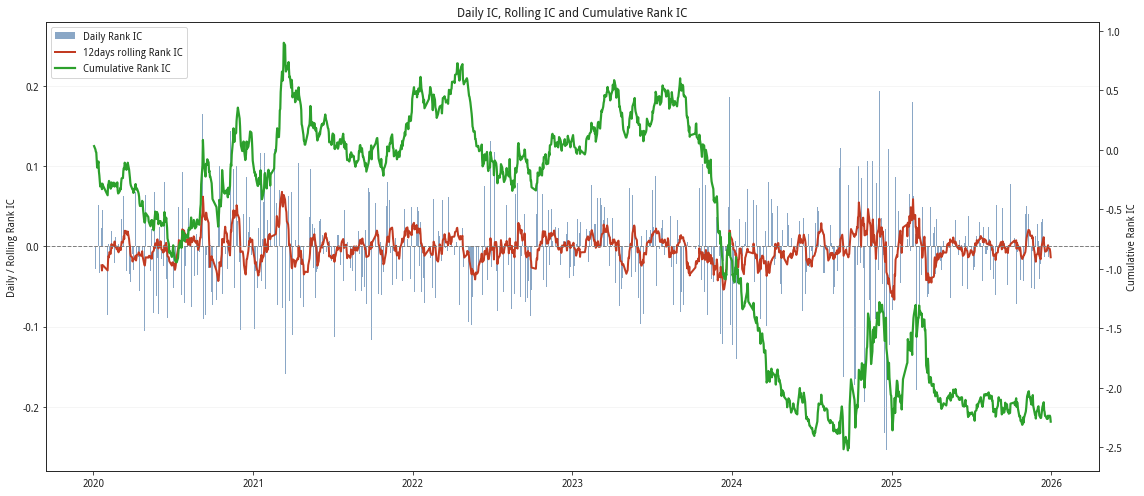

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()